# Analyze grayvalue dynamics in membrane

Goal: obtain water content and profile

In [1]:
import json
import os
import socket
host = socket.gethostname()   
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import dask
import dask.array

# paths
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'

elif host == 'mpc2053.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mpc/homes/fische_r/NAS/DASCOELY/processing'
else:
    print(host+' is not known to the notebook')
    
cwd = os.getcwd()
os.chdir(os.path.join(gitpath, 'EC_lab'))   
from plot_EC_lab_data import load_sample_data, plot_vs_time, plot_HFR_time_color, mpr_to_xr, HFR_color_plot_to_axis
os.chdir(cwd)


EC_path = os.path.join(toppath, 'EC_lab_files')

overview = json.load(open(os.path.join(gitpath, 'meta_and_linking_data','data_overview.json'), 'r'))
    
segmentation_path = os.path.join(toppath, 'processing', '04_membrane_ML')
registered_path = os.path.join(toppathSSD, '02_registered_3p1D')

px = 2.75e-6
vx = px**3

# fetch githash
import subprocess
cwd = os.getcwd()
os.chdir(gitpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)

In [2]:
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
fontprops = fm.FontProperties(size=14)

In [46]:
import pickle

In [47]:
charge_dict_path = os.path.join(toppath, 'processing', 'charge_dict.p')

In [48]:
charge_dict = pickle.load(open(charge_dict_path, 'rb'))

## Experiment with data

In [3]:
sample = '4'
segpath = os.path.join(segmentation_path, sample, sample+'membrane_segmentation.nc')
seg_data = xr.load_dataset(segpath)

In [4]:
regpath = os.path.join(registered_path, '02_'+sample+'_registered_3p1D.nc')
reg_data = xr.open_dataset(regpath)
[ar,br,cr,dr,er,fr] = seg_data.attrs['05_ML_cropping']
images = [im for im in reg_data.keys() if im[3:7] == 'imag']
images.sort()

In [5]:
t_utc_tomo = reg_data['t_utc'].data

In [6]:
a,b,c,d,e,f = seg_data.attrs['cropping of seg data']

In [7]:
shp = reg_data[images[4]][ar:br, cr:dr, er:fr][a:b,c:d,e:f].shape
# shp = data[images[4]][:, c:d, e:f].shape
shp = shp + (len(images),)

In [8]:
im = np.zeros(shp, dtype = np.uint16)

In [9]:
# with obtained cropping data
for i in range(shp[-1]):
    if i%10 == 0:
        print(i)
    im[...,i] = reg_data[images[i]][ar:br, cr:dr, er:fr][a:b, c:d, e:f].data
    # im[...,i] = data[images[i]][:, c:d, e:f].data

0
10
20
30
40
50
60
70


In [10]:
reg_data.close()

In [11]:
im.shape

(781, 88, 1526, 71)

In [12]:
seg_data['segmented'].shape

(801, 108, 1546, 71)

In [29]:
membrane = seg_data['segmented'][a:b,c:d,e:f]==0

In [27]:
test = np.ones(membrane.shape, dtype=np.float16)

In [30]:
test[~membrane] = np.nan

In [31]:
im = im*test

In [33]:
mean_grays = np.nanmean(im, axis = (0,1,2))

In [35]:
med_grays = np.nanmedian(im, axis = (0,1,2))

In [41]:
std_grays = np.nanstd(im, axis = (0,1,2))

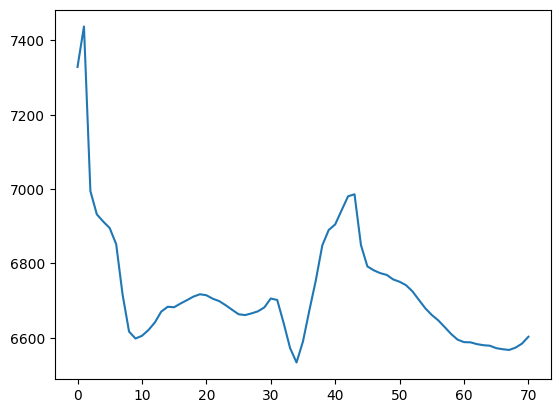

In [39]:
plt.plot(mean_grays)

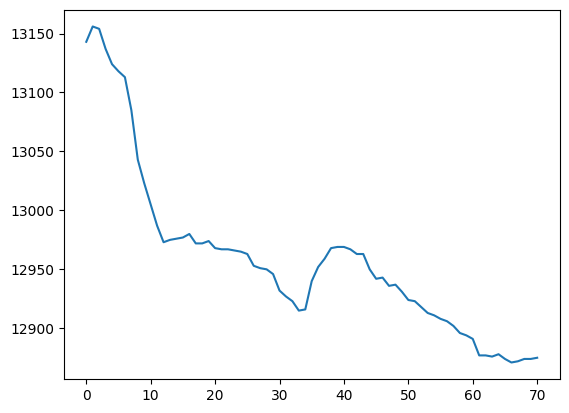

In [45]:
plt.plot(med_grays)

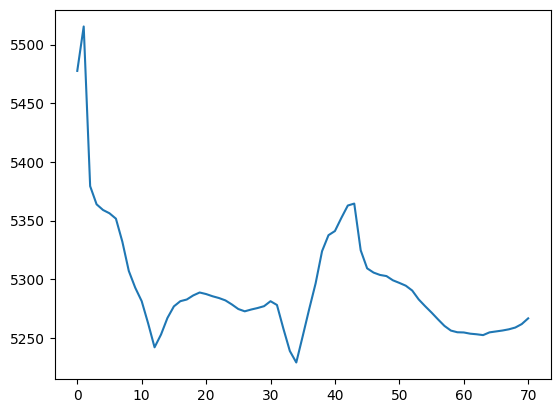

In [42]:
plt.plot(std_grays)

In [52]:
HFR_time = charge_dict[sample]['HFR']['HFRtime']
HFR = charge_dict[sample]['HFR']['fit_HFR']
HFR0 = charge_dict[sample]['HFR']['highfreqR']
t_tomo = charge_dict[sample]['t_utc_tomo'] - charge_dict[sample]['t0']
sat = charge_dict[sample]['saturation']
TH = charge_dict[sample]['TH']
memvol = charge_dict[sample]['membrane volume']
rel_swell = memvol/memvol.min()*100
Q = charge_dict[sample]['Q']
I = -charge_dict[sample]['I']
E = -charge_dict[sample]['E']
time = charge_dict[sample]['time']

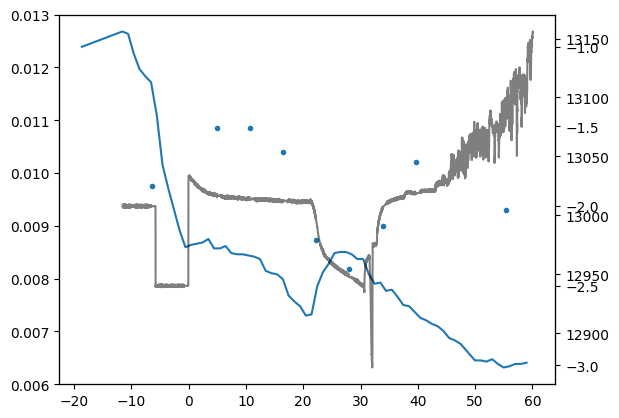

In [59]:
fig, ax = plt.subplots()
ax.plot(HFR_time/60 - 11.5, 1/HFR, '.')
ax.set_ylim(0.006,0.013)
ax2 = ax.twinx()
ax2.plot(t_tomo/60 - 11.5, med_grays)
ax3 = ax.twinx()
ax3.plot(time/60 -11.5, -E, 'k', alpha = 0.5)

In [22]:
import ctypes
def trim_memory() -> int:
    libc = ctypes.CDLL("libc.so.6")
    return libc.malloc_trim(0)

In [32]:
trim_memory()

1